## 04 · EMT-TF expression (unconditional final notebook)

Gate 3 is NA (non-branching), so the unconditional EMT-TF step is the **last** notebook, numbered 04. Widened EMT-TF panel (FOXC / PRRX families, not only Snail/Zeb/Twist), gated on detectable expression; VIM excluded (a mesenchymal marker, not a TF). Deliverable is a **categorical overlay** of thresholded expressers on a grey manifold, not a continuous colormap.

In [ ]:
import os, sys, glob
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [ ]:
name = os.path.basename(os.getcwd())
cat  = os.path.basename(os.path.dirname(os.getcwd()))
pth  = os.path.join(*([os.pardir]*6)); pth_data = os.path.join(pth, 'data')
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_fig = os.path.join(pth, 'figures', 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
os.makedirs(pth_fig, exist_ok=True)

In [ ]:
# read the manifold with signatures + pseudotime; reuse the house linear layout.
adata = sc.read_h5ad(os.path.join(pth_out, 'signatures.h5ad'))
adata.obsm['X_umap'] = adata.obsm['X_umap_lin']
t = adata.obs['t'].values; tn = (t - t.min())/(t.max() - t.min())
print('cells:', adata.shape[0], '| pseudotime', round(t.min(), 2), '->', round(t.max(), 2))

cells: 4089 | pseudotime 0.0 -> 10.43


In [ ]:
# widened EMT-TF panel gated on detectable expression (eval lesson: include FOXC/PRRX
# mesenchymal families, not only Snail/Zeb/Twist). VIM excluded (a marker, not a TF).
# per-TF: detection frac, pseudotime trend (rho), and enriched-end bias.
panel = ['SNAI1', 'SNAI2', 'ZEB1', 'ZEB2', 'TWIST1', 'TWIST2',
         'FOXC1', 'FOXC2', 'PRRX1', 'PRRX2']
present = [g for g in panel if g in adata.var_names]
early = tn <= np.quantile(tn, 1/3); late = tn >= np.quantile(tn, 2/3)
X = adata[:, present].X; X = X.toarray() if hasattr(X, 'toarray') else np.asarray(X)
rows = []
for j, g in enumerate(present):
    x = X[:, j]; rho, p = spearmanr(tn, x); me, ml = x[early].mean(), x[late].mean()
    bias = (ml - me)/(ml + me + 1e-9)
    rows.append((g, round((x > 0).mean(), 3), round(me, 3), round(ml, 3),
                 round(rho, 3), round(bias, 3)))
df = pd.DataFrame(rows, columns=['TF', 'frac_expr', 'mean_early', 'mean_late', 'rho_vs_t', 'end_bias'])
df = df.sort_values('rho_vs_t')
print(df.to_string(index=False))
ok = df[df.frac_expr > 0.03].copy()
tf_lo = ok.sort_values('rho_vs_t').iloc[0]['TF']          # most root-trending detectable factor
tf_hi = ok.sort_values('rho_vs_t').iloc[-1]['TF']         # most terminus-trending detectable factor
def _end_label(g):
    b = float(ok.loc[ok.TF == g, 'end_bias'].iloc[0])
    return 'terminus' if b > 0.05 else ('root' if b < -0.05 else 'pan-tumor')
lab_lo, lab_hi = _end_label(tf_lo), _end_label(tf_hi)
print(f'\ndetectable factors (frac>0.03): {ok.TF.tolist()}')
print(f'derived pair: {tf_lo} ({lab_lo}) <-> {tf_hi} ({lab_hi})')

    TF  frac_expr  mean_early  mean_late  rho_vs_t  end_bias
TWIST2      0.001       0.003      0.000    -0.023    -1.000
 FOXC1      0.002       0.008      0.003    -0.011    -0.436
 SNAI1      0.007       0.032      0.024     0.004    -0.140
 SNAI2      0.033       0.123      0.146     0.021     0.084
TWIST1      0.011       0.007      0.042     0.061     0.728
 PRRX1      0.377       0.958      1.268     0.122     0.139
  ZEB1      0.822       2.835      4.387     0.234     0.215
  ZEB2      0.833       2.714      4.217     0.263     0.217

detectable factors (frac>0.03): ['SNAI2', 'PRRX1', 'ZEB1', 'ZEB2']
derived pair: SNAI2 (terminus) <-> ZEB2 (terminus)


overlay thresholds (top decile among expressers): {'SNAI2': 6.11, 'ZEB2': 5.62} | cells shown: {'SNAI2': 14, 'ZEB2': 341}
SNAI2: 3.3% expressing; 14 shown (top decile), mean pseudotime of shown = 0.09 (all = 0.50)
ZEB2: 83.3% expressing; 341 shown (top decile), mean pseudotime of shown = 0.52 (all = 0.50)
saved expression.pdf


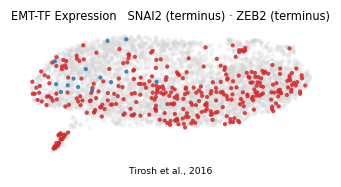

In [ ]:
# deliverable: expression.pdf -- categorical overlay of thresholded expressers on a grey
# manifold (house 3.5,1.5), NOT a continuous colormap. display cutoff = top decile among
# expressing cells, per factor, so a broadly-expressed TF is not washed across the manifold.
xl = adata.obsm['X_umap']
xlo, xhi = np.percentile(xl[:, 0], [0.3, 99.7]); ylo, yhi = np.percentile(xl[:, 1], [0.3, 99.7])
px = (xhi-xlo)*.05; py = (yhi-ylo)*.08
def _vec(g):
    x = adata[:, g].X
    return x.toarray().ravel() if hasattr(x, 'toarray') else np.asarray(x).ravel()
thr = {}
for g in [tf_lo, tf_hi]:
    v = _vec(g); pos = v[v > 0]; thr[g] = float(np.quantile(pos, 0.90)) if pos.size else 0.0
sel = {g: _vec(g) > thr[g] for g in [tf_lo, tf_hi]}
print('overlay thresholds (top decile among expressers):', {g: round(thr[g], 2) for g in thr},
      '| cells shown:', {g: int(sel[g].sum()) for g in sel})
order = sorted([tf_lo, tf_hi], key=lambda g: -int(sel[g].sum()))
colors = {tf_lo: 'tab:blue', tf_hi: 'tab:red'}
labs = {tf_lo: lab_lo, tf_hi: lab_hi}
fig, ax = plt.subplots(figsize=(3.5, 1.5))
sc.pl.umap(adata, size=30, alpha=.3, frameon=False, show=False, ax=ax, na_color='lightgray')
for g in order:
    ap = adata[sel[g]].copy()
    sc.pl.umap(ap, na_color=colors[g], size=30, alpha=.85, frameon=False, show=False, ax=ax)
ax.set_xlim(xlo-px, xhi+px); ax.set_ylim(ylo-py, yhi+py)
ax.set_title(f'EMT-TF Expression   {tf_lo} ({labs[tf_lo]}) \u00b7 {tf_hi} ({labs[tf_hi]})', size=7.5)
ax.text(.5, -.14, 'Tirosh et al., 2016', ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig, 'expression.pdf'), bbox_inches='tight')
for g in [tf_lo, tf_hi]:
    print(f'{g}: {(_vec(g)>0).mean()*100:.1f}% expressing; {int(sel[g].sum())} shown (top decile), '
          f'mean pseudotime of shown = {tn[sel[g]].mean():.2f} (all = {tn.mean():.2f})')
print('saved expression.pdf')